1. Carga los datos de los tres archivos unidos en un DataFrame, y prepáralos
considerando las siguientes etapas:
a. asigna a la variable objetivo num un cero cuando su valor es cero, y un 1 en
otro caso. Muestra la cantidad de valores ausente por atributo. Procésalos
considerando los siguientes criterios:
i. si el atributo presenta un porcentaje de valores ausentes mayor a 25%,
entonces descartamos ese atributo.
ii. para los atributos con valores ausentes menores al 25% se deben
rellenar con el valor promedio del atributo de acuerdo a la clase, es
decir, los valores ausentes para los cuales num=0 se deben rellenar
con el promedio de los valores presentes para los cuales num=0.
iii. Para las variables categóricas, los valores a asignar (promedio) deben
ser aproximados al valor entero más cercano.
b. Construye variables dummies para las variables discretas con tres o más
categorías.
c. Realiza un análisis descriptivo por variable visualizando histogramas y
gráficos de barra según corresponda. Construye una matriz de correlaciones
con un heatmap, para las variables continuas. Plantea tus observaciones y
conclusiones

In [1]:
import warnings
warnings.filterwarnings('ignore')

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from local_utils import plot_descriptive, plot_roc

plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
nombres = pd.read_csv('feature_names.csv', header=None)[0].tolist()
nombres = ['trestbps' if n == 'threstbps' else n for n in nombres]

archivos = sorted(glob.glob('processed.*.data'))
print(archivos)

lista_df = []
for archivo in archivos:
    df_temp = pd.read_csv(archivo, header=None, names=nombres, na_values='?')
    df_temp['origen'] = archivo.split('.')[1]
    lista_df.append(df_temp)

df = pd.concat(lista_df, ignore_index=True)
print(df.shape)
df.head()

['processed.cleveland.data', 'processed.hungarian.data', 'processed.switzerland.data']
(720, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,origen
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland


In [3]:
print('Valores originales de num:')
print(df['num'].value_counts().sort_index())

df['num'] = (df['num'] != 0).astype(int)

print('\nValores de num binarizado:')
print(df['num'].value_counts())

Valores originales de num:
num
0    360
1    209
2     68
3     65
4     18
Name: count, dtype: int64

Valores de num binarizado:
num
0    360
1    360
Name: count, dtype: int64


**Observación:** la variable `num` original va de 0 a 4 (gravedad de la enfermedad). Al binarizarla quedan 360 pacientes sin cardiopatía y 360 con cardiopatía: clases perfectamente balanceadas, por lo que no se requiere balanceo (SMOTE) y el accuracy no está sesgado por la clase mayoritaria.

In [4]:
ausentes = pd.DataFrame({
    'n_ausentes': df.isna().sum(),
    'pct_ausentes': (df.isna().mean() * 100).round(1)
})
ausentes.sort_values('pct_ausentes', ascending=False)

,n_ausentes,pct_ausentes
ca,413,57.4
thal,320,44.4
slope,207,28.7
fbs,83,11.5
chol,23,3.2
oldpeak,6,0.8
trestbps,3,0.4
thalach,2,0.3
exang,2,0.3
restecg,2,0.3


In [5]:
cols_fisiologicas = ['trestbps', 'chol', 'thalach']

print('Cantidad de ceros por clínica:')
print((df[cols_fisiologicas] == 0).groupby(df['origen']).sum())

df.loc[df['chol'] == 0, 'chol'] = np.nan

print(f"\nchol ausentes tras la corrección: {df['chol'].isna().sum()} "
      f"({df['chol'].isna().mean() * 100:.1f}%)")

Cantidad de ceros por clínica:
             trestbps  chol  thalach
origen                              
cleveland           0     0        0
hungarian           0     0        0
switzerland         0   123        0

chol ausentes tras la corrección: 146 (20.3%)


**Observación:** la tabla de ausentes no captura un problema oculto: los 123 pacientes de la clínica de Suiza tienen colesterol (`chol`) igual a 0, valor fisiológicamente imposible. Se interpreta como dato no registrado y se reemplaza por NaN. Con esto `chol` pasa de 3.2% a 20.3% de ausentes; al seguir bajo el 25% se conserva y se imputa por clase.

In [6]:
pct_ausentes = df.isna().mean() * 100
cols_descartar = pct_ausentes[pct_ausentes > 25].index.tolist()
print('Columnas descartadas (>25% ausentes):', cols_descartar)

df = df.drop(columns=cols_descartar)
print('Dimensión tras descartar:', df.shape)

Columnas descartadas (>25% ausentes): ['slope', 'ca', 'thal']
Dimensión tras descartar: (720, 12)


**Observación:** se descartan `slope` (28.7%), `ca` (57.4%) y `thal` (44.4%) por superar el 25% de valores ausentes. Clínicamente son variables relevantes, pero imputar más de un cuarto de sus valores introduciría demasiada información artificial.

In [7]:
cols_categoricas = ['sex', 'cp', 'fbs', 'restecg', 'exang']

cols_con_ausentes = df.columns[df.isna().any()].tolist()
print('Columnas a imputar:', cols_con_ausentes)

valores_imputacion = df.groupby('num')[cols_con_ausentes].mean()
for col in cols_con_ausentes:
    if col in cols_categoricas:
        valores_imputacion[col] = valores_imputacion[col].round()

print('\nValores de imputación por clase:')
print(valores_imputacion.round(2))

for col in cols_con_ausentes:
    df[col] = df[col].fillna(df['num'].map(valores_imputacion[col]))

print('\nAusentes restantes:', df.isna().sum().sum())

Columnas a imputar: ['trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak']

Valores de imputación por clase:
     trestbps    chol  fbs  restecg  thalach  exang  oldpeak
num                                                         
0      129.91  241.27  0.0      1.0   150.93    0.0     0.39
1      133.70  258.93  0.0      1.0   130.20    1.0     1.19

Ausentes restantes: 0


**Observación:** los ausentes se imputan con el promedio por clase (num=0 / num=1), redondeando las variables categóricas. La tabla de imputación ya anticipa diferencias: los pacientes con cardiopatía presentan menor frecuencia cardíaca máxima (130 vs 151), mayor depresión del ST (oldpeak 1.19 vs 0.39) y más angina por ejercicio. Nota metodológica: en `restecg` (0, 1, 2) el promedio redondeado es 1 en ambas clases, que corresponde a la categoría menos frecuente; para categóricas, la moda sería una alternativa más natural. Se sigue el criterio del enunciado; el impacto es acotado (2 pacientes).

In [15]:
df[cols_categoricas] = df[cols_categoricas].astype(int)

cols_multicategoria = [c for c in cols_categoricas if df[c].nunique() >= 3]
print('Variables con 3 o más categorías:')
for c in cols_multicategoria:
    print(f'  {c}: {sorted(df[c].unique().tolist())}')

df_modelo = pd.get_dummies(
    df.drop(columns=['origen']),
    columns=cols_multicategoria,
    dtype=int
)
print('\nDimensión de df_modelo:', df_modelo.shape)
print(df_modelo.columns.tolist())

Variables con 3 o más categorías:
  cp: [1, 2, 3, 4]
  restecg: [0, 1, 2]

Dimensión de df_modelo: (720, 16)
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'num', 'cp_1', 'cp_2', 'cp_3', 'cp_4', 'restecg_0', 'restecg_1', 'restecg_2']


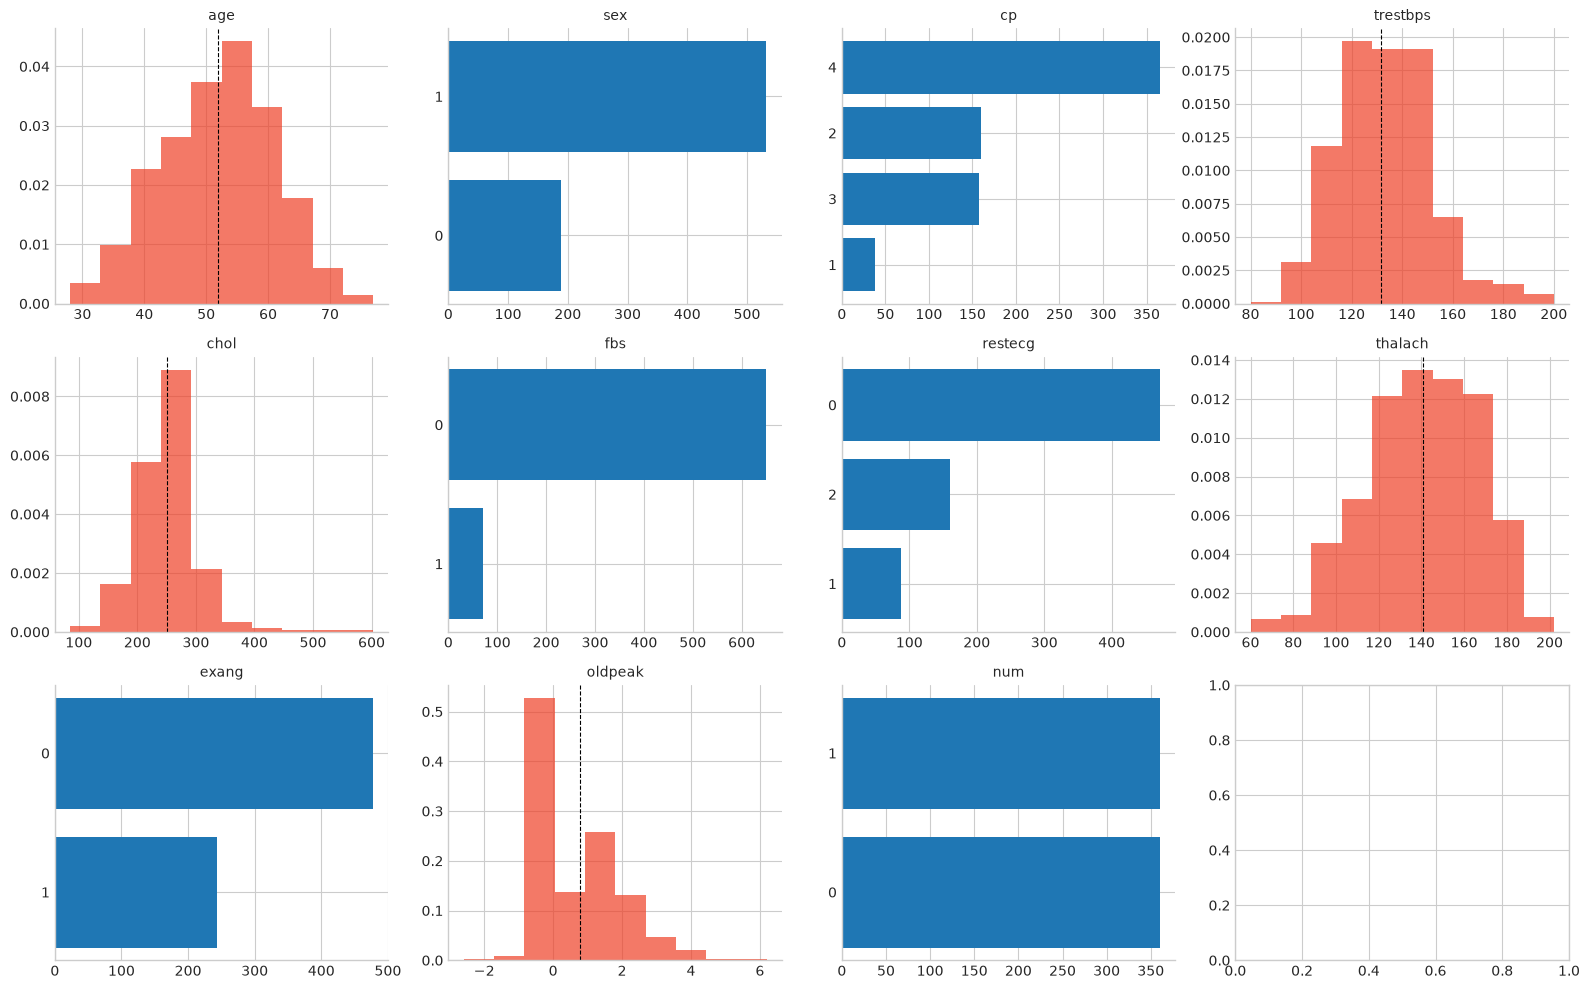

In [16]:
plot_descriptive(
    df.drop(columns=['origen']),
    ncols=4,
    figsize=(16, 10),
    plot_type='hist'
)

Observaciones del análisis descriptivo

**Continuas:** `age` (28–77 años, media 52), `trestbps` (media 132 mm Hg) y `thalach` (media 141) tienen distribuciones aproximadamente normales. `oldpeak` es fuertemente asimétrica (mayoría en 0, cola hasta 6.2) y presenta 11 valores negativos, todos de la clínica de Suiza, posiblemente por una convención de registro distinta. `chol` tiene valores extremos (12 pacientes sobre 400 mg/dl).

**Categóricas:** la muestra es mayoritariamente masculina (~74%), y la cardiopatía es más frecuente en hombres (59%) que en mujeres (25%). En `cp`, la categoría más común es "asintomático" (4), que concentra la mayor proporción de enfermos (78%), un patrón conocido de isquemia silenciosa. `fbs` y `exang` están desbalanceadas hacia 0. La variable objetivo está balanceada (360/360).

**Advertencia sobre `chol` (fuga de información):** el pico en el histograma se debe a la imputación por clase. Los 146 valores imputados quedan en dos valores exactos: 258.93 (120 pacientes, todos con cardiopatía) y 241.27 (26 pacientes, todos sanos). Como la imputación usa la variable objetivo, un modelo podría aprender que "chol = 258.93 ⇒ enfermo", una regla artificial. Se mantiene el criterio del enunciado, pero se revisará su efecto en la importancia de variables (paso 5).

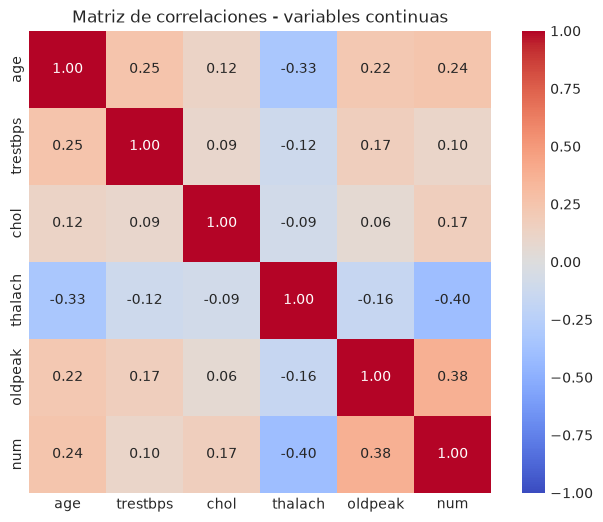

In [17]:
cols_continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
corr = df[cols_continuas + ['num']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True)
plt.title('Matriz de correlaciones - variables continuas')
plt.show()

### Observaciones de la matriz de correlaciones

- Las variables continuas más asociadas a la cardiopatía son `thalach` (−0.40), donde los enfermos alcanzan menor frecuencia cardíaca máxima, y `oldpeak` (+0.38), donde mayor depresión del ST indica isquemia durante el esfuerzo. Le sigue `age` (+0.24).
- `chol` muestra una correlación débil (+0.17), parcialmente inflada por la imputación por clase (ver advertencia anterior). `trestbps` prácticamente no se relaciona linealmente con la enfermedad (+0.10).
- Entre predictores, la correlación más alta es `age`–`thalach` (−0.33), coherente fisiológicamente. No hay multicolinealidad relevante (todas |r| < 0.35), por lo que se conservan todas las variables.

### Conclusiones del paso 1

Se unieron 720 pacientes de tres clínicas, con clases balanceadas (360/360). Se descartaron `slope`, `ca` y `thal` por exceso de ausentes, se detectó y corrigió el colesterol no registrado en Suiza (ceros), y se imputaron los ausentes por clase según el enunciado. Las variables con mayor señal son `thalach`, `oldpeak`, el tipo de dolor torácico (`cp` asintomático) y el sexo. Las relaciones lineales individuales son moderadas, lo que sugiere que modelos no lineales como los ensambles secuenciales pueden aportar al combinar variables.

2. Divide la muestra en entrenamiento y test (33%), y con ello:
a. entrena un modelo de ensamble secuencial AdaBoost
b. entrena un modelo de ensamble secuencial Gradient Boosting
c. entrena un modelo de ensamble secuencial XGBoosting
Para cada uno, utiliza hiper parámetros por defecto y muestra su desempeño usando
las métricas adecuadas. Comenta

In [18]:
#2. Modelos de ensamble secuencial con hiperparámetros por defecto
#División de la muestra en entrenamiento y test (33%), y entrenamiento de AdaBoost, Gradient Boosting y XGBoost.

from sklearn.model_selection import train_test_split

X = df_modelo.drop(columns=['num'])
y = df_modelo['num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('\nProporción de clases en train:')
print(y_train.value_counts(normalize=True).round(3))
print('\nProporción de clases en test:')
print(y_test.value_counts(normalize=True).round(3))

Train: (482, 15) | Test: (238, 15)

Proporción de clases en train:
num
1    0.5
0    0.5
Name: proportion, dtype: float64

Proporción de clases en test:
num
1    0.5
0    0.5
Name: proportion, dtype: float64


In [19]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import classification_report, f1_score, roc_auc_score

def evaluar_modelo(modelo, nombre):
    yhat_train = modelo.predict(X_train)
    yhat_test = modelo.predict(X_test)

    print(f'===== {nombre} =====')
    print('Métricas en train:')
    print(classification_report(y_train, yhat_train, digits=3))
    print('Métricas en test:')
    print(classification_report(y_test, yhat_test, digits=3))

    return {
        'modelo': nombre,
        'f1_train': f1_score(y_train, yhat_train),
        'f1_test': f1_score(y_test, yhat_test),
        'auc_test': roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1])
    }

resultados = []

ada_default = AdaBoostClassifier(random_state=42)
ada_default.fit(X_train, y_train)
resultados.append(evaluar_modelo(ada_default, 'AdaBoost (default)'))

===== AdaBoost (default) =====
Métricas en train:
              precision    recall  f1-score   support

           0      0.836     0.846     0.841       241
           1      0.845     0.834     0.839       241

    accuracy                          0.840       482
   macro avg      0.840     0.840     0.840       482
weighted avg      0.840     0.840     0.840       482

Métricas en test:
              precision    recall  f1-score   support

           0      0.852     0.824     0.838       119
           1      0.829     0.857     0.843       119

    accuracy                          0.840       238
   macro avg      0.841     0.840     0.840       238
weighted avg      0.841     0.840     0.840       238



**Observación AdaBoost (default):** accuracy y F1 de 0.84 tanto en train como en test, sin señales de sobreajuste, coherente con un ensamble de árboles de profundidad 1. Detecta el 85.7% de los pacientes con cardiopatía (recall clase 1), con aproximadamente 17 falsos negativos en test, el error más costoso en un contexto clínico.

In [20]:
from sklearn.ensemble import GradientBoostingClassifier

gboost_default = GradientBoostingClassifier(random_state=42)
gboost_default.fit(X_train, y_train)

params = gboost_default.get_params()
print('Hiperparámetros por defecto:',
      {k: params[k] for k in ['n_estimators', 'learning_rate', 'max_depth', 'subsample']})
print()

resultados.append(evaluar_modelo(gboost_default, 'Gradient Boosting (default)'))

Hiperparámetros por defecto: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 1.0}

===== Gradient Boosting (default) =====
Métricas en train:
              precision    recall  f1-score   support

           0      0.959     0.963     0.961       241
           1      0.963     0.959     0.960       241

    accuracy                          0.961       482
   macro avg      0.961     0.961     0.961       482
weighted avg      0.961     0.961     0.961       482

Métricas en test:
              precision    recall  f1-score   support

           0      0.851     0.815     0.833       119
           1      0.823     0.857     0.840       119

    accuracy                          0.836       238
   macro avg      0.837     0.836     0.836       238
weighted avg      0.837     0.836     0.836       238



**Observación Gradient Boosting (default):** alcanza 0.961 de accuracy en train pero 0.836 en test: una brecha de ~12 puntos que indica sobreajuste. Con árboles de profundidad 3 y 100 iteraciones, el modelo memoriza patrones del entrenamiento que no generalizan. En test su desempeño es prácticamente igual al de AdaBoost (F1 clase 1: 0.840 vs 0.843; mismo recall de 0.857), con levemente más falsos positivos. Su mayor capacidad no se traduce en mejor generalización con los hiperparámetros por defecto, lo que motiva la búsqueda de hiperparámetros.

In [21]:
import json
from xgboost import XGBClassifier

xgb_default = XGBClassifier(random_state=42)
xgb_default.fit(X_train, y_train)

config = json.loads(xgb_default.get_booster().save_config())
param_arbol = config['learner']['gradient_booster']['tree_train_param']
print('Hiperparámetros por defecto:',
      '| learning_rate:', param_arbol['eta'],
      '| max_depth:', param_arbol['max_depth'],
      '| subsample:', param_arbol['subsample'],
      '| n_estimators:', xgb_default.get_booster().num_boosted_rounds())
print()

resultados.append(evaluar_modelo(xgb_default, 'XGBoost (default)'))

Hiperparámetros por defecto: | learning_rate: 0.300000012 | max_depth: 6 | subsample: 1 | n_estimators: 100

===== XGBoost (default) =====
Métricas en train:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000       241
           1      1.000     1.000     1.000       241

    accuracy                          1.000       482
   macro avg      1.000     1.000     1.000       482
weighted avg      1.000     1.000     1.000       482

Métricas en test:
              precision    recall  f1-score   support

           0      0.803     0.790     0.797       119
           1      0.793     0.807     0.800       119

    accuracy                          0.798       238
   macro avg      0.798     0.798     0.798       238
weighted avg      0.798     0.798     0.798       238



**Observación XGBoost (default):** clasifica perfectamente el entrenamiento (accuracy 1.000) pero cae a 0.798 en test, una brecha de 20 puntos: es el modelo con mayor sobreajuste y el peor desempeño en test, con recall de la clase 1 de 0.807 (≈23 falsos negativos). Sus valores por defecto (max_depth=6, learning_rate=0.3) son agresivos para un dataset de 482 observaciones de entrenamiento: los árboles profundos memorizan casos individuales y los pasos grandes amplifican ese efecto.

In [22]:
df_resultados = pd.DataFrame(resultados).set_index('modelo')
df_resultados['brecha_f1'] = df_resultados['f1_train'] - df_resultados['f1_test']
df_resultados.round(3).sort_values('f1_test', ascending=False)

,f1_train,f1_test,auc_test,brecha_f1
modelo,,,,
AdaBoost (default),0.839,0.843,0.912,-0.004
Gradient Boosting (default),0.960,0.840,0.909,0.121
XGBoost (default),1.000,0.800,0.896,0.200


Con hiperparámetros por defecto, el desempeño en test es inversamente proporcional a la complejidad del modelo: AdaBoost (árboles de profundidad 1) obtiene el mejor F1 y AUC sin sobreajuste, Gradient Boosting (profundidad 3) iguala prácticamente su desempeño en test pero con una brecha de 12 puntos, y XGBoost (profundidad 6, learning_rate 0.3) memoriza el entrenamiento y es el que peor generaliza. Con solo 482 observaciones de entrenamiento, los modelos más complejos necesitan ajuste de hiperparámetros para controlar el sobreajuste.

**Modelo con mejor F1: AdaBoost.** Se realiza la búsqueda de hiperparámetros sobre él (n_estimators y learning_rate; `subsample` no existe en AdaBoost). Como Gradient Boosting queda prácticamente empatado (diferencia de 0.003) y tiene mayor margen de mejora al controlar su sobreajuste, se realiza también la grilla completa sobre él.

3. Realiza una búsqueda del hiper parámetro para el modelo que resulte tener mejor
desempeño (utiliza f1-score para determinarlo). Los valores a buscar para la grilla
son:
a. n_estimators: 20 a 200 con 15 valores
b. learning_rate: 0.004 a 1.0 con 40 valores
c. sub_sample: 0.1 a 1.0 con 18 valores

In [23]:
import time
from sklearn.model_selection import GridSearchCV, StratifiedKFold

grilla_ada = {
    'n_estimators': np.linspace(20, 200, 15).astype(int),
    'learning_rate': np.linspace(0.004, 1.0, 40)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

inicio = time.time()
ada_grid = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    param_grid=grilla_ada,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)
ada_grid.fit(X_train, y_train)
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} minutos')

print('Mejores hiperparámetros:', ada_grid.best_params_)
print(f'Mejor F1 en validación cruzada: {ada_grid.best_score_:.4f}')

Tiempo de búsqueda: 1.8 minutos
Mejores hiperparámetros: {'learning_rate': np.float64(1.0), 'n_estimators': np.int64(200)}
Mejor F1 en validación cruzada: 0.8207


In [24]:
ada_opt = ada_grid.best_estimator_
resultados.append(evaluar_modelo(ada_opt, 'AdaBoost (optimizado)'))

===== AdaBoost (optimizado) =====
Métricas en train:
              precision    recall  f1-score   support

           0      0.863     0.892     0.878       241
           1      0.888     0.859     0.873       241

    accuracy                          0.876       482
   macro avg      0.876     0.876     0.875       482
weighted avg      0.876     0.876     0.875       482

Métricas en test:
              precision    recall  f1-score   support

           0      0.858     0.815     0.836       119
           1      0.824     0.866     0.844       119

    accuracy                          0.840       238
   macro avg      0.841     0.840     0.840       238
weighted avg      0.841     0.840     0.840       238



**Observación AdaBoost optimizado (learning_rate=1.0, n_estimators=200):** ambos hiperparámetros quedan en el límite superior de la grilla, lo que indica que AdaBoost se beneficia de mayor capacidad (con árboles de profundidad 1 casi no sobreajusta). Sin embargo, la mejora en test es marginal: F1 clase 1 de 0.844 (vs 0.843 por defecto) y recall de 0.866 (un paciente enfermo más detectado). En train sube a 0.876, manteniendo una brecha baja (~3 puntos). Los hiperparámetros por defecto ya estaban cerca del techo de desempeño de AdaBoost en estos datos.

In [ ]:
grilla_gb = {
    'n_estimators': np.linspace(20, 200, 15).astype(int),
    'learning_rate': np.linspace(0.004, 1.0, 40),
    'subsample': np.linspace(0.1, 1.0, 18)
}

inicio = time.time()
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid=grilla_gb,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
gb_grid.fit(X_train, y_train)
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} minutos')

print('Mejores hiperparámetros:', gb_grid.best_params_)
print(f'Mejor F1 en validación cruzada: {gb_grid.best_score_:.4f}')

**Nota metodológica:** la grilla completa (10.800 combinaciones × 5 folds = 54.000 entrenamientos) con GridSearchCV resultó ineficiente: cada entrenamiento dura fracciones de segundo y el proceso coordinador se convierte en cuello de botella, dejando ociosos a los núcleos. Se implementa la misma búsqueda aprovechando que, en Gradient Boosting, un modelo de 200 árboles contiene en sus primeras etapas a los modelos de 20, 32, ..., 187 árboles. Para cada combinación de learning_rate y subsample se entrena un solo modelo de 200 árboles por fold y se evalúan los 15 valores de n_estimators con `staged_predict`. Se usan los mismos folds que en AdaBoost. Resultado equivalente con 15 veces menos entrenamientos (3.600).

In [26]:
from joblib import Parallel, delayed
from itertools import product
from sklearn.metrics import f1_score

valores_n = np.linspace(20, 200, 15).astype(int)
valores_lr = np.linspace(0.004, 1.0, 40)
valores_sub = np.linspace(0.1, 1.0, 18)

folds = list(cv.split(X_train, y_train))

def evaluar_combinacion(lr, sub):
    f1_folds = np.zeros((len(folds), len(valores_n)))
    for i, (idx_tr, idx_val) in enumerate(folds):
        modelo = GradientBoostingClassifier(
            n_estimators=valores_n.max(), learning_rate=lr,
            subsample=sub, random_state=42
        )
        modelo.fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])

        j = 0
        for etapa, yhat in enumerate(modelo.staged_predict(X_train.iloc[idx_val]), start=1):
            if etapa == valores_n[j]:
                f1_folds[i, j] = f1_score(y_train.iloc[idx_val], yhat)
                j += 1
                if j == len(valores_n):
                    break

    return [
        {'learning_rate': lr, 'subsample': sub, 'n_estimators': n,
         'f1_cv': f1_folds[:, j].mean()}
        for j, n in enumerate(valores_n)
    ]

inicio = time.time()
salida = Parallel(n_jobs=-1)(
    delayed(evaluar_combinacion)(lr, sub)
    for lr, sub in product(valores_lr, valores_sub)
)
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} minutos')

df_grilla_gb = pd.DataFrame([fila for bloque in salida for fila in bloque])
print('Combinaciones evaluadas:', len(df_grilla_gb))

mejor_gb = df_grilla_gb.loc[df_grilla_gb['f1_cv'].idxmax()]
print('\nMejores hiperparámetros:')
print(mejor_gb)
df_grilla_gb.sort_values('f1_cv', ascending=False).head(10)

Tiempo de búsqueda: 6.2 minutos
Combinaciones evaluadas: 10800

Mejores hiperparámetros:
learning_rate     0.055077
subsample         0.470588
n_estimators     58.000000
f1_cv             0.840423
Name: 648, dtype: float64


,learning_rate,subsample,n_estimators,f1_cv
648,0.055077,0.470588,58,0.840423
649,0.055077,0.470588,71,0.839435
1010,0.080615,0.788235,84,0.838299
700,0.055077,0.629412,148,0.838230
1009,0.080615,0.788235,71,0.837466
696,0.055077,0.629412,97,0.836995
741,0.055077,0.788235,97,0.836911
462,0.029538,0.735294,174,0.836866
461,0.029538,0.735294,161,0.836779
2881,0.259385,0.735294,32,0.836573


**Observación grilla Gradient Boosting:** la mejor combinación es learning_rate=0.055, subsample=0.47 y n_estimators=58, con F1 de validación cruzada de 0.840 (vs 0.821 de AdaBoost optimizado en los mismos folds). Los tres hiperparámetros reducen la capacidad de memorización respecto a los valores por defecto (0.1, 1.0, 100), coherente con el sobreajuste observado en el paso 2: pasos más cortos y cada árbol entrenado con menos de la mitad de los pacientes, lo que introduce aleatoriedad y regulariza el modelo. Las 10 mejores combinaciones tienen F1 entre 0.837 y 0.840, lo que indica una zona estable de hiperparámetros (learning_rate entre 0.03 y 0.08, subsample entre 0.47 y 0.79) y no un óptimo aislado. Además se observa el compromiso entre learning_rate y n_estimators: tasas más bajas requieren más árboles.

In [27]:
gb_opt = GradientBoostingClassifier(
    n_estimators=int(mejor_gb['n_estimators']),
    learning_rate=mejor_gb['learning_rate'],
    subsample=mejor_gb['subsample'],
    random_state=42
)
gb_opt.fit(X_train, y_train)
resultados.append(evaluar_modelo(gb_opt, 'Gradient Boosting (optimizado)'))

===== Gradient Boosting (optimizado) =====
Métricas en train:
              precision    recall  f1-score   support

           0      0.880     0.913     0.896       241
           1      0.909     0.876     0.892       241

    accuracy                          0.894       482
   macro avg      0.895     0.894     0.894       482
weighted avg      0.895     0.894     0.894       482

Métricas en test:
              precision    recall  f1-score   support

           0      0.862     0.790     0.825       119
           1      0.806     0.874     0.839       119

    accuracy                          0.832       238
   macro avg      0.834     0.832     0.832       238
weighted avg      0.834     0.832     0.832       238



**Observación Gradient Boosting optimizado:** la regularización reduce la brecha train–test de F1 de 12 a ~5 puntos (0.892 vs 0.839), confirmando que learning_rate y subsample controlan el sobreajuste. Obtiene el mejor recall de la clase 1 de todos los modelos (0.874: 15 falsos negativos de 119 enfermos), a costa de una menor precision (0.806). En F1 de test queda prácticamente empatado con AdaBoost optimizado (0.839 vs 0.844, diferencia menor a un paciente).

In [28]:
df_resultados = pd.DataFrame(resultados).set_index('modelo')
df_resultados['brecha_f1'] = df_resultados['f1_train'] - df_resultados['f1_test']
df_resultados.round(3).sort_values('f1_test', ascending=False)

,f1_train,f1_test,auc_test,brecha_f1
modelo,,,,
AdaBoost (optimizado),0.873,0.844,0.912,0.029
AdaBoost (default),0.839,0.843,0.912,-0.004
Gradient Boosting (default),0.960,0.840,0.909,0.121
Gradient Boosting (optimizado),0.892,0.839,0.920,0.053
XGBoost (default),1.000,0.800,0.896,0.200


La optimización tuvo efectos distintos según el modelo. En AdaBoost la mejora es marginal (F1 test 0.843 → 0.844): sus valores por defecto ya estaban cerca de su techo. En Gradient Boosting, la búsqueda no subió el F1 en test, pero redujo el sobreajuste a menos de la mitad (brecha 0.121 → 0.053) y logró el mayor AUC (0.920) y el mayor recall de la clase 1 (0.874). Los cuatro mejores modelos quedan dentro de 0.005 de F1 en test, una diferencia menor a un paciente; la elección final se apoya en las curvas ROC (paso 4).
Paso 4: curvas ROC

4. Elabora un gráfico con las curvas ROC para cada modelo entrenado, y a partir de ello
recomienda alguno de ellos. Justifica la decisión


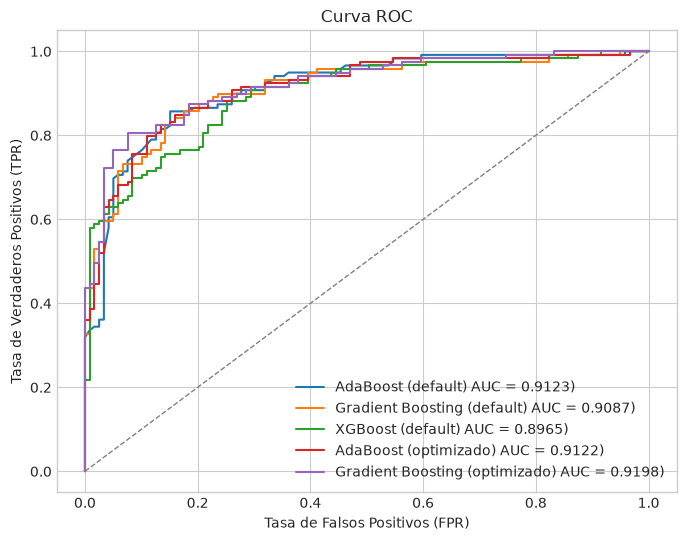

In [29]:
modelos = [ada_default, gboost_default, xgb_default, ada_opt, gb_opt]
nombres_modelos = ['AdaBoost (default)', 'Gradient Boosting (default)',
                   'XGBoost (default)', 'AdaBoost (optimizado)',
                   'Gradient Boosting (optimizado)']

plot_roc(X_test, y_test, modelos, nombres_modelos)

Las cinco curvas ROC se ubican muy por sobre la diagonal (AUC entre 0.897 y 0.920), por lo que todos los modelos discriminan bien. XGBoost con valores por defecto queda por debajo del resto en la zona FPR 0.1–0.3, reflejo de su sobreajuste.

**Se recomienda Gradient Boosting optimizado** (learning_rate=0.055, subsample=0.47, n_estimators=58), por la convergencia de varios criterios:

1. **Mayor AUC (0.920)** y mejor curva en la zona de baja tasa de falsos positivos (FPR < 0.10), donde detecta entre 72% y 80% de los enfermos.
2. **Mayor recall de la clase 1 (0.874):** es el modelo que menos enfermos deja sin detectar, el error más costoso en un contexto clínico.
3. **Mejor F1 en validación cruzada (0.840 vs 0.821 de AdaBoost optimizado)**, evaluado sobre los mismos folds: su ventaja no depende solo de la partición de test.
4. **Sobreajuste controlado** (brecha F1 de 0.053, frente a 0.121 con valores por defecto).

Como contrapunto, AdaBoost optimizado tiene un F1 de test levemente mayor (0.844 vs 0.839, menos de un paciente de diferencia) y es un modelo más simple. Dado que las diferencias en test son mínimas y el test tiene solo 238 pacientes, se privilegia el modelo con mejor desempeño en validación cruzada y en detección de enfermos.

5. Muestra las variables por nivel de importancia para el mejor modelo, luego de la
búsqueda de hiper parámetro. Comenta.


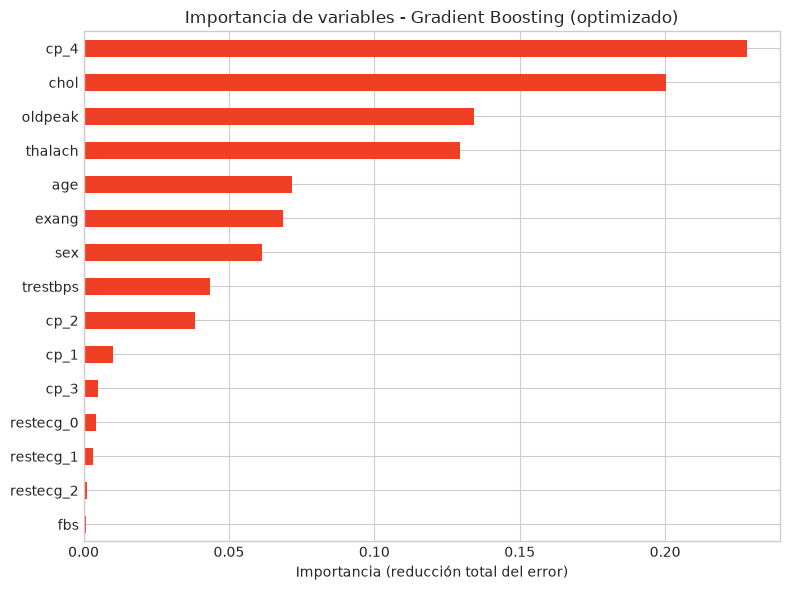

cp_4         0.228
chol         0.200
oldpeak      0.134
thalach      0.129
age          0.072
exang        0.069
sex          0.061
trestbps     0.043
cp_2         0.038
cp_1         0.010
cp_3         0.005
restecg_0    0.004
restecg_1    0.003
restecg_2    0.001
fbs          0.001
dtype: float64


In [30]:
importancias = pd.Series(gb_opt.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(8, 6))
importancias.plot(kind='barh', color='xkcd:tomato')
plt.title('Importancia de variables - Gradient Boosting (optimizado)')
plt.xlabel('Importancia (reducción total del error)')
plt.tight_layout()
plt.show()

print(importancias.sort_values(ascending=False).round(3))

### Observaciones de la importancia de variables

Las variables más relevantes para el modelo recomendado son `cp_4` (dolor torácico asintomático, 0.228), `chol` (0.200), `oldpeak` (0.134) y `thalach` (0.129), seguidas de `age`, `exang` y `sex` (0.06–0.07). `fbs` y las categorías de `restecg` prácticamente no aportan (≤ 0.004).

La mayoría es coherente con el análisis descriptivo: el dolor asintomático concentra la mayor proporción de enfermos (78%), y `oldpeak` y `thalach` son las variables continuas con mayor correlación con la enfermedad.

**`chol` es la excepción y requiere cautela.** Su correlación con la enfermedad es débil (0.17), pero el modelo la usa como segunda variable más importante. Esta desproporción se explica por la imputación por clase exigida en el paso 1: 120 pacientes con cardiopatía quedaron con `chol` = 258.93 exacto (y 26 sanos con 241.27), de modo que el valor imputado codifica la clase. El modelo aprende "chol = 258.93 ⇒ enfermo", una regla artificial que no existiría con pacientes nuevos, cuya clase se desconoce al momento de imputar. Por lo tanto, la importancia de `chol` y parte del desempeño de los modelos están probablemente sobreestimados por fuga de información (*data leakage*). Una imputación sin usar la variable objetivo (por ejemplo, la mediana calculada solo en entrenamiento) evitaría este problema.

## Conclusión final

**Objetivo:** construir y comparar tres modelos de ensamble secuencial (AdaBoost, Gradient Boosting y XGBoost) para detectar cardiopatía en 720 pacientes de tres clínicas (Cleveland, Hungría y Suiza).

### Preparación de los datos
- La variable objetivo `num` se binarizó, quedando clases perfectamente balanceadas (360/360), por lo que no se requirió técnica de balanceo.
- Se descartaron `slope`, `ca` y `thal` por superar el 25% de valores ausentes.
- Se detectó un problema no evidente en la tabla de ausentes: los 123 pacientes de Suiza tenían colesterol igual a 0, valor fisiológicamente imposible, que se trató como dato no registrado.
- Los ausentes restantes se imputaron con el promedio por clase, según el enunciado, y se crearon variables dummies para `cp` y `restecg`.

### Resultados

| Modelo | F1 test | AUC test | Brecha F1 (train − test) |
|---|---|---|---|
| AdaBoost (optimizado) | 0.844 | 0.912 | 0.029 |
| AdaBoost (default) | 0.843 | 0.912 | −0.004 |
| Gradient Boosting (default) | 0.840 | 0.909 | 0.121 |
| Gradient Boosting (optimizado) | 0.839 | **0.920** | 0.053 |
| XGBoost (default) | 0.800 | 0.896 | 0.200 |

- **Con hiperparámetros por defecto, a mayor complejidad, mayor sobreajuste.** AdaBoost (árboles de profundidad 1) no sobreajusta; Gradient Boosting (profundidad